# Comprendre PyPSA et le modèle du réseau québécois de Nathan

Ce notebook a deux objectifs :

1. **Apprendre PyPSA** à partir de zéro, sur de tout petits réseaux qu'on peut vérifier à la main.
2. **Comprendre le code de Nathan** (`network/`) : pourquoi chaque script existe, ce qu'il fait au réseau,
   et vérifier ses résultats en relançant les calculs ici, sur ses fichiers `.nc`.

| Partie | Contenu |
|---|---|
| 0 | Mise en route (environnement, chemins) |
| 1 | PyPSA de base : objets, composants, DC PF, AC PF, LOPF, types de nœuds |
| 2 | La physique derrière les choix de Nathan : ligne longue, compensation série, effet Ferranti, St Clair |
| 3 | Vue d'ensemble du pipeline de Nathan (les 3 topologies) |
| 4 | Explorer le réseau 315 kV résolu (`elec_solved.nc`) : carte, lignes, parc, demande, dispatch LOPF |
| 5 | `run_pf.py` : préparer et lancer un AC power flow (et pourquoi le 315 kV diverge) |
| 6 | `reduce_to_735kv.py` : réduction par plus court chemin dans le graphe |
| 7 | Corrections du 735 kV : nombre de circuits et compensation série (on refait 110/168 → 168/168) |
| 8 | Réactances et condensateurs shunt (`add_shunt_impedance.py`) |
| 9 | Résultats sur carte + analyse N-1 directement dans PyPSA |
| 10 | Lien avec tes scripts `Jean_tests` (MATPOWER / pandapower) |
| 11 | Limites connues, pistes, et annexe PyPSA 0.30 vs 1.x |

> Toutes les cellules ont été exécutées avec **PyPSA 1.3.0** (la version de ton `pypsa-env`) sur les fichiers
> de `network/networks_current/` du commit `c7154893`. Les chiffres affichés sont donc des résultats réels,
> pas recopiés de la doc — et on les compare à la doc de Nathan au fur et à mesure.

## 0. Mise en route

**Noyau Jupyter.** Ton `pypsa-env` n'a pas encore `ipykernel`. Une fois, dans un terminal :

```
pypsa-env\Scripts\activate
pip install ipykernel
python -m ipykernel install --user --name pypsa-env --display-name "Python (pypsa-env)"
```

Puis choisis le noyau *Python (pypsa-env)* dans VS Code / Jupyter. La partie 10 utilise `pandapower`
(installé dans `pp-env`, pas dans `pypsa-env`) : elle se saute toute seule s'il est absent.

**Version de PyPSA.** Les scripts de Nathan ont été écrits pour **PyPSA 0.30.x** (voir `network/README.md`).
Ce notebook tourne sous PyPSA 1.x : il *importe* les fonctions de Nathan qui fonctionnent encore
(`run_pf.prepare_for_ac_pf`, `apply_compensation`, `build_full_graph`, `st_clair`…), mais certains de ses scripts
complets (ex. `run_lopf_main_island.py`, qui utilise `n.mremove`) plantent sous 1.x. Voir l'annexe à la fin.

In [1]:
import sys, io, contextlib, logging, warnings, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import pypsa

warnings.filterwarnings("ignore")
for name in ["pypsa", "linopy", "highspy"]:
    logging.getLogger(name).setLevel(logging.ERROR)

# Trouve la racine du dépôt (le dossier qui contient network/run_pf.py), où que soit lancé le notebook
REPO = Path.cwd().resolve()
while not (REPO / "network" / "run_pf.py").exists() and REPO != REPO.parent:
    REPO = REPO.parent
NET = REPO / "network"
CUR = NET / "networks_current"
sys.path.insert(0, str(NET))          # pour pouvoir faire `import run_pf` etc.

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 140, "display.max_columns", 30)

@contextlib.contextmanager
def silence():
    # Les scripts de Nathan impriment beaucoup : on coupe la sortie quand on n'en a pas besoin.
    with contextlib.redirect_stdout(io.StringIO()):
        yield

print("PyPSA", pypsa.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)
print("Dépôt :", REPO)
print("Réseaux :", sorted(p.name for p in CUR.glob("*.nc")))

PyPSA 1.3.0 | pandas 2.3.3 | numpy 2.4.6
Dépôt : C:\Users\jeanf\OneDrive - McGill University\JARVIS\Cours\2026 Fall\ECSE 458\quebec-pypsa-earth
Réseaux : ['elec_735kv.nc', 'elec_735kv_shunt.nc', 'elec_735kv_shunt_pf.nc', 'elec_reduced.nc', 'elec_solved.nc']


---
# Partie 1 — PyPSA de base

## 1.1 L'idée centrale : un `Network` = des tableaux pandas

Un `pypsa.Network` est un conteneur. Chaque **type de composant** (bus, ligne, générateur…) est un
`DataFrame` pandas, une ligne par objet, une colonne par attribut :

| Accès | Contenu |
|---|---|
| `n.buses`, `n.lines`, `n.generators`, `n.loads`, `n.storage_units`, `n.links`, `n.transformers`, `n.shunt_impedances` | attributs **statiques** (un nombre par objet) |
| `n.loads_t.p_set`, `n.generators_t.p`, `n.buses_t.v_mag_pu`, `n.lines_t.p0`… | attributs **temporels** : DataFrame *temps × objets* |
| `n.snapshots` | l'index temporel (ici 168 heures, du 1er au 7 janvier 2022) |

Les entrées s'appellent `*_set` (ce que tu imposes : `p_set`, `q_set`, `v_mag_pu_set`) et les sorties sont
`p`, `q`, `p0`/`p1` (flux aux deux bouts d'une branche), `v_mag_pu`, `v_ang`.

Trois « solveurs » principaux :

| Méthode | Ce que c'est | Résout | Ignore |
|---|---|---|---|
| `n.lpf()` | **DC power flow** (linéaire) | angles, flux P | tensions (=1 pu), Q, pertes, r |
| `n.pf()` | **AC power flow** Newton-Raphson | V, θ, P, Q partout | les limites (s_nom, V min/max ne sont pas imposées) |
| `n.optimize()` | **LOPF** : dispatch économique optimal avec contraintes DC du réseau | qui produit combien, flux | Q, tensions |

**Unités** : puissances en MW / MVAr / MVA, tensions nominales `v_nom` en kV, impédances de lignes `r`, `x` en Ω,
susceptance `b` en S. PyPSA calcule lui-même les per-unit (`x_pu`, `b_pu`…) dans `n.calculate_dependent_values()`.

## 1.2 Premier réseau : 2 nœuds (ton `test_pyPSA.py`)

In [2]:
n = pypsa.Network()
n.add("Bus", "b1", v_nom=735)
n.add("Bus", "b2", v_nom=735)
n.add("Generator", "slack", bus="b1", control="Slack")       # la source qui équilibre tout
n.add("Line", "L", bus0="b1", bus1="b2", x=50, r=5)          # Ohms
n.add("Load", "charge", bus="b2", p_set=1000, q_set=300)     # MW, MVAr
n.pf()

print(n.buses_t.v_mag_pu.round(4))
print((np.degrees(n.buses_t.v_ang)).round(2), "(degrés)")
print("\nFlux sur la ligne : P0 =", n.lines_t.p0.iloc[0, 0].round(1), "MW au départ, P1 =",
      n.lines_t.p1.iloc[0, 0].round(1), "MW à l'arrivée  -> pertes =",
      (n.lines_t.p0 + n.lines_t.p1).iloc[0, 0].round(2), "MW")
# NB : avec un générateur sans p_set, PyPSA 1.3 laisse generators_t.p du slack à NaN ; on lit l'injection au nœud dans buses_t.p
print(f"La source fournit P = {n.buses_t.p.iloc[0]['b1']:.1f} MW, Q = {n.generators_t.q.iloc[0, 0]:.1f} MVAr")

name       b1      b2
snapshot             
now       1.0  0.9569
name       b1    b2
snapshot           
now       0.0 -5.38 (degrés)

Flux sur la ligne : P0 = 1011.0 MW au départ, P1 = -1000.0 MW à l'arrivée  -> pertes = 11.02 MW
La source fournit P = 1011.0 MW, Q = 410.2 MVAr


**Vérification à la main.** PyPSA travaille en per-unit sur une base de **1 MVA** pour les lignes :
$Z_{base} = V_{nom}^2 / 1\,\text{MVA} = 735^2 = 540\,225\ \Omega$, donc $x_{pu} = 50/540\,225$, et la charge vaut $S = 1000 + j300$ pu.
On peut résoudre ce 2-nœuds avec une simple itération de point fixe (méthode de Gauss) :
$V_2 \leftarrow V_1 - z\,\overline{(S/V_2)}$. Newton-Raphson (ce que fait `n.pf()`) converge vers la même solution, plus vite.

In [3]:
z = (5 + 50j) / 735**2       # impédance en pu (base 1 MVA)
S = 1000 + 300j              # charge en pu
V1, V2 = 1.0 + 0j, 1.0 + 0j
for k in range(50):
    V2 = V1 - z * np.conj(S / V2)
print(f"À la main : |V2| = {abs(V2):.4f} pu, angle = {np.degrees(np.angle(V2)):.2f}°")
print(f"PyPSA     : |V2| = {n.buses_t.v_mag_pu.iloc[0]['b2']:.4f} pu, angle = {np.degrees(n.buses_t.v_ang.iloc[0]['b2']):.2f}°")
print("\nCe que PyPSA a calculé tout seul dans n.lines :")
print(n.lines[["r", "x", "r_pu", "x_pu"]])

À la main : |V2| = 0.9569 pu, angle = -5.38°
PyPSA     : |V2| = 0.9569 pu, angle = -5.38°

Ce que PyPSA a calculé tout seul dans n.lines :
        r     x      r_pu      x_pu
name                               
L     5.0  50.0  0.000009  0.000093


## 1.3 Types de nœuds : Slack, PV, PQ

En AC power flow, chaque nœud a 2 inconnues parmi (P, Q, |V|, θ) :

| Type | On impose | On calcule | Dans PyPSA |
|---|---|---|---|
| **Slack** (1 par sous-réseau) | \|V\|, θ = 0 | P, Q | `Generator.control = "Slack"` |
| **PV** (centrale qui régule sa tension) | P, \|V\| | Q, θ | `Generator.control = "PV"` + `Bus.v_mag_pu_set` |
| **PQ** (charge, ou générateur à Q fixe) | P, Q | \|V\|, θ | par défaut |

⚠️ Le type est porté par le **générateur**, pas par le bus, et PyPSA ne lit que `Generator.control`
(jamais `StorageUnit.control`). C'est pour ça que Nathan ajoute des **générateurs « placeholder » à 0 MW** sur les nœuds
qui n'ont que du stockage hydro (`run_lopf_main_island.py`, `run_pf.py`).

⚠️ Un générateur PV dans PyPSA a une **réserve de Q illimitée** (pas de `q_max`) — limite importante notée par Nathan.

Démo : on met un compensateur (générateur PV à P = 0) au nœud de charge. La tension remonte à 1.00 pu exactement,
et on lit le Q qu'il a dû fournir pour y arriver.

In [4]:
n.add("Generator", "compensateur", bus="b2", control="PV", p_set=0)
n.buses.loc["b2", "v_mag_pu_set"] = 1.0
n.pf()
print("V :", n.buses_t.v_mag_pu.round(4).iloc[0].to_dict())
print("Q fourni (MVAr) :", n.generators_t.q.round(1).iloc[0].to_dict())

V : {'b1': 1.0, 'b2': 1.0}
Q fourni (MVAr) : {'slack': -53.2, 'compensateur': 447.8}


## 1.4 Snapshots, LOPF, DC PF, AC PF sur un petit réseau à 3 nœuds

Un mini-« Québec » : de l'hydro bon marché au **Nord**, du gaz cher au **Sud**, la charge à **Montréal**.
On fait varier la charge sur 24 h. On lance :

1. **LOPF** (`n.optimize`) : quel dispatch coûte le moins cher en respectant les limites des lignes ?
2. **DC PF** (`n.lpf`) avec ce dispatch imposé : on doit retrouver exactement les mêmes flux (c'est ce que fait `run_pf.py --method lpf`).
3. **AC PF** (`n.pf`) : est-ce physiquement faisable avec les tensions et la puissance réactive ?

LOPF : ok optimal | coût total = 527579 $


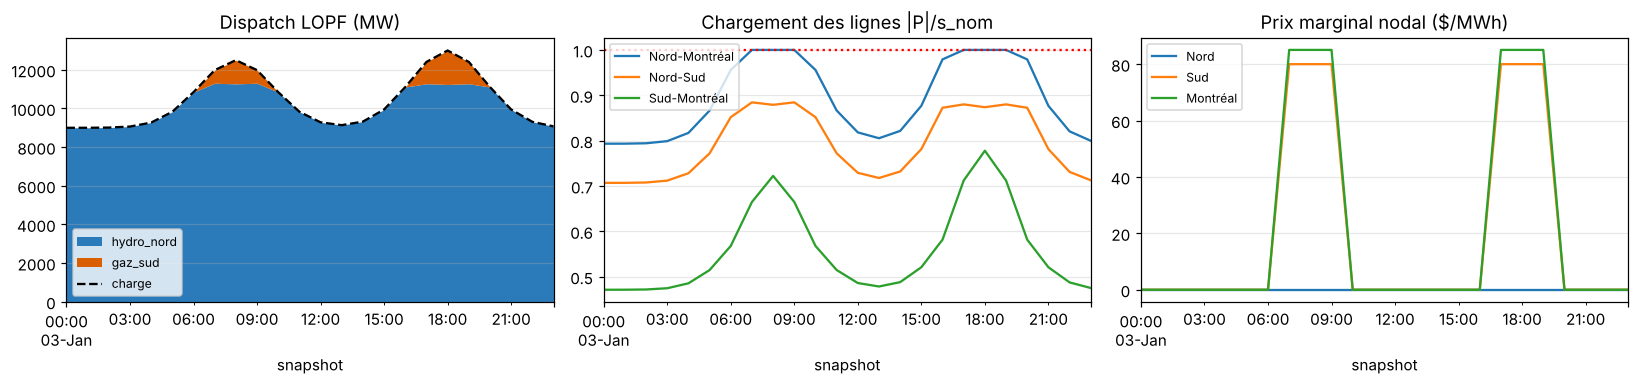

In [5]:
def mini_quebec():
    m = pypsa.Network()
    m.set_snapshots(pd.date_range("2022-01-03", periods=24, freq="h"))
    for b, (x, y) in {"Nord": (-77, 53), "Sud": (-72, 45.5), "Montréal": (-73.6, 45.5)}.items():
        m.add("Bus", b, v_nom=735, x=x, y=y)
    hq735 = pd.read_csv(NET / "hq_line_characteristics_by_voltage.csv", comment="#").set_index("voltage_kv").loc[735]
    for nom, b0, b1, L, s_nom in [("Nord-Montréal", "Nord", "Montréal", 900, 6000),
                                  ("Nord-Sud", "Nord", "Sud", 950, 6000),
                                  ("Sud-Montréal", "Sud", "Montréal", 60, 9000)]:
        m.add("Line", nom, bus0=b0, bus1=b1, length=L, s_nom=s_nom, num_parallel=3,
              r=hq735.r_ohm_per_km * L / 3, x=hq735.xl_ohm_per_km * L / 3 * 0.4,   # 3 circuits, 60 % de compensation
              b=hq735.bc_uS_per_km * 1e-6 * L * 3)
    m.add("Generator", "hydro_nord", bus="Nord", p_nom=14000, marginal_cost=0, control="Slack")
    m.add("Generator", "gaz_sud", bus="Sud", p_nom=4000, marginal_cost=80, control="PV")
    h = np.arange(24)
    charge = 9000 + 3500 * np.exp(-((h - 8) / 2.5) ** 2) + 4000 * np.exp(-((h - 18) / 2.5) ** 2)
    m.add("Load", "Montréal", bus="Montréal", p_set=pd.Series(charge, index=m.snapshots))
    return m

m = mini_quebec()
status, cond = m.optimize(solver_name="highs", log_to_console=False)
print("LOPF :", status, cond, "| coût total =", round(m.objective), "$")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
m.generators_t.p.plot.area(ax=ax[0], color=["#2b7bba", "#d95f02"], linewidth=0)
m.loads_t.p_set.sum(axis=1).plot(ax=ax[0], color="k", ls="--", label="charge")
ax[0].set_title("Dispatch LOPF (MW)"); ax[0].legend(fontsize=8)
(m.lines_t.p0.abs() / m.lines.s_nom).plot(ax=ax[1]); ax[1].axhline(1, color="r", ls=":")
ax[1].set_title("Chargement des lignes |P|/s_nom"); ax[1].legend(fontsize=8)
m.buses_t.marginal_price.plot(ax=ax[2]); ax[2].set_title("Prix marginal nodal ($/MWh)"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Lecture.** Tant que les lignes Nord→Sud ne sont pas saturées, tout vient de l'hydro (prix = 0 $/MWh partout).
Aux pointes, la ligne Nord-Montréal atteint `s_nom` (100 %) : on **doit** allumer le gaz au Sud, et le prix nodal saute à
80 $/MWh au Sud alors qu'il reste à 0 au Nord. C'est la **congestion**. Pourquoi Montréal paie-t-il *plus* que le gaz (≈ 85 $/MWh) ?
Pour livrer 1 MW de plus à Montréal, le gaz doit monter de plus d'1 MW : une partie de son injection repart par Sud→Nord→Montréal
et chargerait la ligne saturée, donc il faut baisser l'hydro d'autant. Remarque : la répartition du flux entre les deux
chemins n'est pas un choix — elle est imposée par les réactances (loi des mailles de Kirchhoff), que la LOPF respecte.

Le *prix marginal* n'existe pas dans `elec_solved.nc` de Nathan (les variables duales n'ont pas été sauvegardées).

In [6]:
# DC PF avec le dispatch LOPF imposé -> mêmes flux
flux_lopf = m.lines_t.p0.copy()
m.generators_t.p_set = m.generators_t.p.copy()          # ce que fait use_lopf_dispatch_as_setpoints() dans run_pf.py
m.lpf()
print("Écart max DC PF vs LOPF :", float((m.lines_t.p0 - flux_lopf).abs().max().max()), "MW")
print("Plus grand angle (DC) entre deux bouts de ligne :",
      round(float(np.degrees((m.buses_t.v_ang[m.lines.bus0].values - m.buses_t.v_ang[m.lines.bus1].values)).__abs__().max()), 1), "°")

# AC PF : on ajoute un Q aux charges (facteur de puissance 0,95, comme run_pf.py) et on lance Newton-Raphson
m.loads_t.q_set = m.loads_t.p_set * np.tan(np.arccos(0.95))
res = m.pf(use_seed=True)    # use_seed : part de la solution DC plutôt que du « flat start » 1 pu / 0°
print("\nAC PF convergé :", int(res.converged.all(axis=1).sum()), "/", len(m.snapshots), "heures")
print(f"Tension min / max : {m.buses_t.v_mag_pu.min().min():.3f} / {m.buses_t.v_mag_pu.max().max():.3f} pu")
print("Pertes actives moyennes :", round(float((m.lines_t.p0 + m.lines_t.p1).sum(axis=1).mean()), 1), "MW")
print("\nFlux DC vs AC à 18h (MW) :")
print(pd.DataFrame({"DC (LOPF)": flux_lopf.iloc[18], "AC": m.lines_t.p0.iloc[18]}).round(0))

Écart max DC PF vs LOPF : 1.2732925824820995e-11 MW
Plus grand angle (DC) entre deux bouts de ligne : 25.2 °



AC PF convergé : 24 / 24 heures
Tension min / max : 0.985 / 1.000 pu
Pertes actives moyennes : 331.0 MW

Flux DC vs AC à 18h (MW) :
               DC (LOPF)      AC
name                            
Nord-Montréal     6000.0  6162.0
Nord-Sud          5242.0  5500.0
Sud-Montréal      7000.0  7077.0


**À retenir.** DC et AC donnent des flux actifs proches (le DC néglige pertes et tensions), mais seul l'AC dit si les
**tensions** tiennent et combien de **réactif** il faut. Toute la difficulté du projet de Nathan est là : la LOPF du 315 kV
trouve 0 % de délestage, mais l'AC PF du même dispatch ne converge pas.

---
# Partie 2 — La physique derrière les choix de Nathan

On reprend une ligne 735 kV de 500 km avec les **paramètres réels d'Hydro-Québec** (`hq_line_characteristics_by_voltage.csv`,
la seule source de r/x/b du projet) et on augmente la charge au bout jusqu'à ce que l'AC PF ne converge plus.
Astuce : chaque *snapshot* = un niveau de charge différent, donc un seul `n.pf()` balaie toute la courbe.

On compare trois cas, qui correspondent exactement aux deux corrections de Nathan sur le 735 kV :
1 circuit (ce que donnait OSM sur certains corridors), 3 circuits (`correct_sending_end_circuits.py`),
3 circuits + 70 % de compensation série (`apply_series_compensation.py`).

            r_ohm_per_km  xl_ohm_per_km  bc_uS_per_km  zc_ohm
voltage_kv                                                   
315                0.028           0.36           4.3     290
735                0.010           0.33           4.9     260


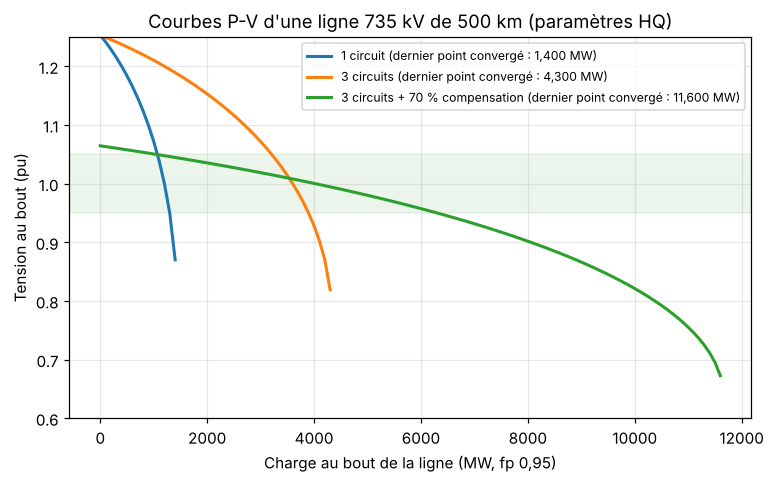

In [7]:
HQ = pd.read_csv(NET / "hq_line_characteristics_by_voltage.csv", comment="#").set_index("voltage_kv")
print(HQ.loc[[315, 735], ["r_ohm_per_km", "xl_ohm_per_km", "bc_uS_per_km", "zc_ohm"]])

def ligne_longue(P_MW, L_km=500, n_circ=1, comp=0.0, reactance_MVAr=0.0, fp=0.95):
    # Source (slack, 1.0 pu) --- ligne 735 kV --- charge P + jQ
    r = HQ.loc[735]
    n = pypsa.Network()
    n.set_snapshots(range(len(P_MW)))
    n.add("Bus", "Source", v_nom=735); n.add("Bus", "Charge", v_nom=735)
    n.add("Generator", "centrale", bus="Source", control="Slack")
    n.add("Line", "L", bus0="Source", bus1="Charge", length=L_km, num_parallel=n_circ, s_nom=1e5,
          r=r.r_ohm_per_km * L_km / n_circ,                       # même formule que apply_hq_line_characteristics.py
          x=r.xl_ohm_per_km * L_km / n_circ * (1 - comp),          # même formule que apply_series_compensation.py
          b=r.bc_uS_per_km * 1e-6 * L_km * n_circ)
    P = pd.Series(np.asarray(P_MW, float), index=n.snapshots)
    n.add("Load", "charge", bus="Charge", p_set=P, q_set=P * np.tan(np.arccos(fp)))
    if reactance_MVAr:
        n.add("ShuntImpedance", "reactance", bus="Charge", b=-reactance_MVAr / 735**2)  # b<0 = réactance
    res = n.pf()
    ok = res.converged.all(axis=1)
    return n.buses_t.v_mag_pu["Charge"].where(ok), n

P = np.arange(0, 12001, 100)
cas = {"1 circuit": dict(n_circ=1), "3 circuits": dict(n_circ=3), "3 circuits + 70 % compensation": dict(n_circ=3, comp=0.7)}
fig, ax = plt.subplots(figsize=(8, 4.5))
for nom, kw in cas.items():
    V, _ = ligne_longue(P, **kw)
    ax.plot(P, V.values, lw=2, label=f"{nom} (dernier point convergé : {P[V.notna().values].max():,.0f} MW)")
ax.axhspan(0.95, 1.05, color="g", alpha=0.08); ax.set_ylim(0.6, 1.25)
ax.set_xlabel("Charge au bout de la ligne (MW, fp 0,95)"); ax.set_ylabel("Tension au bout (pu)")
ax.set_title("Courbes P-V d'une ligne 735 kV de 500 km (paramètres HQ)"); ax.legend(fontsize=8)
plt.show()

**Lecture.** Chaque courbe tombe puis s'arrête : c'est le **nez de la courbe P-V**. Au-delà, il n'existe plus de solution
(la jacobienne devient singulière) : c'est l'**effondrement de tension**, et Newton-Raphson ne converge plus. Ce n'est pas un
problème numérique, c'est de la physique : $P_{max} \approx \dfrac{V_s V_r}{X}\sin\delta$.

- Diviser `num_parallel` par 3 multiplie $X$ par 3 et divise la capacité de transfert d'autant. C'est le bug OSM que corrige
  `correct_sending_end_circuits.py` sur 5 corridors (114-1291, 114-148, 340-457, 66-457, 651-25) : **89 → 110 / 168 heures**.
- La compensation série 70 % retire 70 % de $X$ : **110 → 168 / 168**. Hydro-Québec compense réellement ses longues lignes 735 kV
  (mais le 70 % est une hypothèse de Nathan, pas une valeur mesurée).

Le modèle de PyPSA est un **π nominal** (r, x, b concentrés) — pour 500 km un π exact (fonctions hyperboliques) serait un peu
différent, mais l'ordre de grandeur est le bon.

## 2.2 Effet Ferranti : surtension à faible charge → réactances shunt

Une ligne 735 kV produit du réactif par sa capacité ($Q \approx V^2 b$). Sous sa **SIL** (*surge impedance loading*,
$V^2/Z_c \approx 2\,080$ MW par circuit 735 kV), elle produit plus de réactif qu'elle n'en consomme ($I^2X$) et la tension
**monte** au bout. C'est la surtension de nuit que Nathan observe (00h–03h). Une réactance shunt (`ShuntImpedance` avec `b < 0`)
absorbe ce réactif.

SIL d'un circuit 735 kV = 2,078 MW ; charging d'un circuit de 500 km ≈ 1,324 MVAr à 1 pu


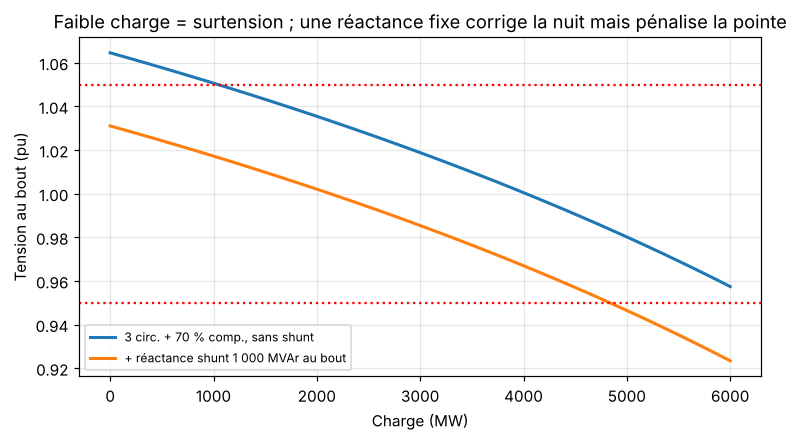

In [8]:
SIL = 735**2 / HQ.loc[735, "zc_ohm"]
print(f"SIL d'un circuit 735 kV = {SIL:,.0f} MW ; charging d'un circuit de 500 km ≈ "
      f"{735**2 * HQ.loc[735,'bc_uS_per_km']*1e-6*500:,.0f} MVAr à 1 pu")
P = np.arange(0, 6001, 100)
fig, ax = plt.subplots(figsize=(8, 4))
for nom, kw in {"3 circ. + 70 % comp., sans shunt": dict(n_circ=3, comp=0.7),
                "+ réactance shunt 1 000 MVAr au bout": dict(n_circ=3, comp=0.7, reactance_MVAr=1000)}.items():
    V, _ = ligne_longue(P, **kw)
    ax.plot(P, V.values, lw=2, label=nom)
ax.axhline(1.05, color="r", ls=":"); ax.axhline(0.95, color="r", ls=":")
ax.set_xlabel("Charge (MW)"); ax.set_ylabel("Tension au bout (pu)"); ax.legend(fontsize=8)
ax.set_title("Faible charge = surtension ; une réactance fixe corrige la nuit mais pénalise la pointe"); plt.show()

C'est exactement le compromis du §8 : un shunt **fixe** (`b` constant, pas de dimension temporelle dans PyPSA) ne peut pas
suivre la demande. Il faudrait des bancs commutés ou des SVC.

## 2.3 La courbe de St Clair (`st_clair.py`) : d'où vient `s_nom`

Pour le `s_nom` des lignes (la limite que la LOPF respecte), Nathan utilise la courbe de St Clair, construite analytiquement
avec les paramètres HQ : $P/\text{SIL} = \min\big(3{,}5\ ;\ \sin 30° / \sin(\beta L)\big)$, puis **× 3** dans
`run_lopf_main_island.py` (`ST_CLAIR_MARGIN_FACTOR`).

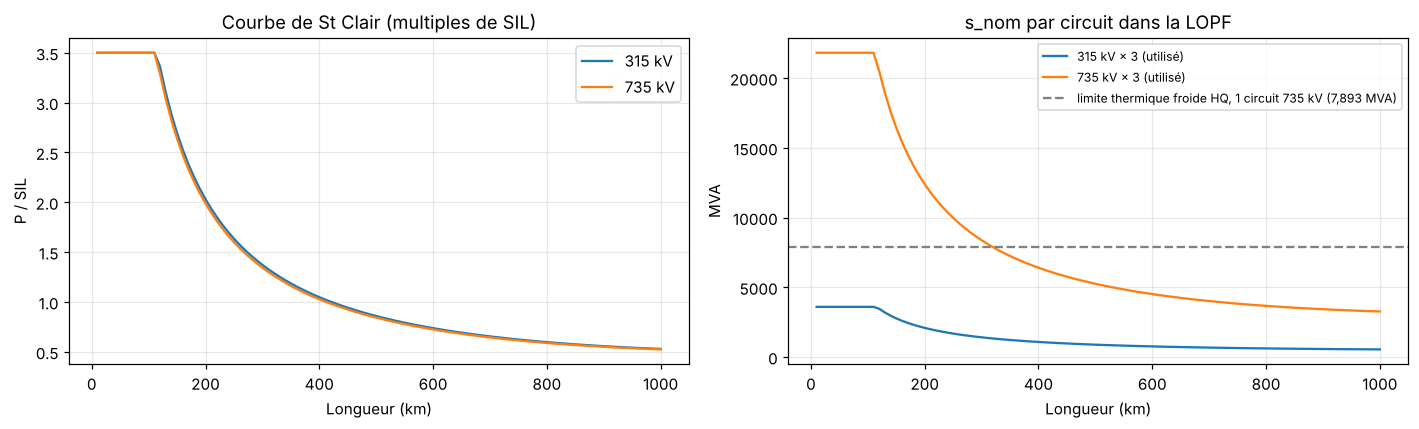

In [9]:
import st_clair
ref = st_clair.load_line_params()
L = np.arange(10, 1001, 10)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for v in [315, 735]:
    ax[0].plot(L, [st_clair.st_clair_loadability_pu(l, v, ref) for l in L], label=f"{v} kV")
    ax[1].plot(L, [3 * st_clair.st_clair_s_nom_mva(l, v, ref) for l in L], label=f"{v} kV × 3 (utilisé)")
S_froid = np.sqrt(3) * 735 * float(HQ.loc[735, "thermal_capacity_a_cold"]) / 1000   # MVA = √3·V·I
ax[1].axhline(S_froid, color="gray", ls="--", label=f"limite thermique froide HQ, 1 circuit 735 kV ({S_froid:,.0f} MVA)")
ax[0].set(title="Courbe de St Clair (multiples de SIL)", xlabel="Longueur (km)", ylabel="P / SIL")
ax[1].set(title="s_nom par circuit dans la LOPF", xlabel="Longueur (km)", ylabel="MVA")
ax[0].legend(); ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

Le × 3 surestime les lignes courtes (~2,8 × la limite thermique HQ) — Nathan le signale dans `ASSUMPTIONS_AND_LIMITATIONS.md`.
Conséquence pratique : les **% de chargement** des lignes dans ses résultats sont relatifs à ce `s_nom` gonflé.

---
# Partie 3 — Le pipeline de Nathan en un coup d'œil

```
PyPSA-Earth (snakemake, OSM)  ──►  elec.nc
   │  corrections de données « une fois pour toutes » :
   │    regional_demand.py + rescale_demand_regional.py   → vraie demande HQ par région/municipalité
   │    fix_line_lengths_from_geometry.py                  → 10 longueurs de lignes absurdes
   │    build_hq_contracts_data.py + attach_real_generators.py → vraies centrales HQ + producteurs privés
   │    attach_hydro_dispatch_2022.py                      → plafonds horaires réels de l'hydro 2022
   │    add_churchill_falls_tie.py                         → la ligne 735 kV de Churchill Falls (absente d'OSM)
   │    apply_hq_line_characteristics.py                   → r/x/b HQ sur toutes les lignes 315/735 kV
   ▼
elec_full.nc        ① NON RÉDUIT : ~4 000 nœuds, tout le Canada, toutes tensions (carte de référence)
   │  reduce_voltage_network.py   → ne garde que ≥ 315 kV (rattache le reste au plus proche, à vol d'oiseau)
   │  fix_parallel_circuits_v2.py → vrais nombres de circuits sur les corridors ≥ 315 kV
   │  correction manuelle de capacité (14 centrales manquantes, éolien/solaire mis à l'échelle HQ)
   ▼
elec_reduced.nc
   │  run_lopf_main_island.py     → plus grande île, coûts, plafonds réels, St Clair ×3, délestage VOLL, slack, LOPF
   ▼
elec_solved.nc      ② 315 kV : 205 nœuds, LOPF 0 % délestage — mais AC PF 1/168
   │  reduce_to_735kv.py          → seulement le squelette 735/765 kV (agrégation par plus court chemin)
   ▼
elec_735kv.nc       ③ 735 kV : 58 nœuds, AC PF 89/168
   │  correct_sending_end_circuits.py → 3 circuits sur 5 corridors      → 110/168
   │  apply_series_compensation.py    → 70 % sur 15 lignes             → 168/168
   │  add_shunt_impedance.py          → 5 condensateurs + 11 réactances → 168/168, 0,966–1,059 pu
   ▼
elec_735kv_shunt.nc ──► export_to_matpower.py ──► quebec_735kv.m (ce que tes scripts pandapower lisent)
```

Les trois topologies ne sont **pas** trois versions de la même chose : ① est la vérité terrain brute, ② le réseau de travail
(dispatch économique), ③ un réseau taillé pour que l'AC PF converge et qu'on puisse faire de la contingence.

**Conventions de Nathan à garder** : chaque hypothèse générique est documentée là où elle est introduite ; les contournements
de PyPSA passent par un *générateur placeholder à 0 MW* ; plus court chemin dans le graphe > distance à vol d'oiseau (mais
« plus juste » ≠ « converge mieux », testé et annulé sur le 315 kV) ; on vérifie tout par un vrai re-calcul avant de l'écrire.

---
# Partie 4 — Explorer le réseau 315 kV résolu (`elec_solved.nc`)

In [10]:
s = pypsa.Network(CUR / "elec_solved.nc")
composants = ["buses", "lines", "links", "transformers", "loads", "generators", "storage_units", "shunt_impedances"]
print(pd.Series({c: len(getattr(s, c)) for c in composants}, name="nombre").to_string())
print("\nSnapshots :", s.snapshots[0], "→", s.snapshots[-1], f"({len(s.snapshots)} h)")
print("\nNiveaux de tension des nœuds (kV) :", s.buses.v_nom.value_counts().to_dict())
s.buses.head()

buses               205
lines               276
links                 5
transformers         22
loads               647
generators          262
storage_units        22
shunt_impedances      0

Snapshots : 2022-01-01 00:00:00 → 2022-01-07 23:00:00 (168 h)

Niveaux de tension des nœuds (kV) : {315.0: 140, 735.0: 56, 450.0: 5, 765.0: 2, 345.0: 2}


,v_nom,type,x,y,carrier,unit,location,v_mag_pu_set,v_mag_pu_min,v_mag_pu_max,control,generator,sub_network,under_construction,tag_area,lon,lat,substation_lv,substation_off,symbol,tag_substation,country
name,,,,,,,,,,,,,,,,,,,,,,
1,315.0,,-73.4999,45.4436,AC,,,1.0,0.0,inf,PQ,,,0.0,0.0,-73.4999,45.4436,0.0,1.0,substation,transmission,CA
2,735.0,,-73.4989,45.4446,AC,,,1.0,0.0,inf,PQ,,,0.0,0.0,-73.4989,45.4446,0.0,1.0,substation,transmission,CA
24,315.0,,-71.2925,46.8084,AC,,,1.0,0.0,inf,PQ,,,0.0,0.0,-71.2925,46.8084,0.0,1.0,substation,transmission,CA
25,735.0,,-71.2915,46.8094,AC,,,1.0,0.0,inf,PQ,,,0.0,0.0,-71.2915,46.8094,0.0,1.0,substation,transmission,CA
42,315.0,,-73.3597,45.6116,AC,,,1.0,0.0,inf,PQ,,,0.0,0.0,-73.3597,45.6116,0.0,1.0,substation,transmission,CA


### 4.1 Carte

Pas besoin de fond de carte : `n.buses.x` / `n.buses.y` sont la longitude / latitude. Les scripts `visualize_*.py` de Nathan font
la même chose en Plotly ; ici une version matplotlib minimale.

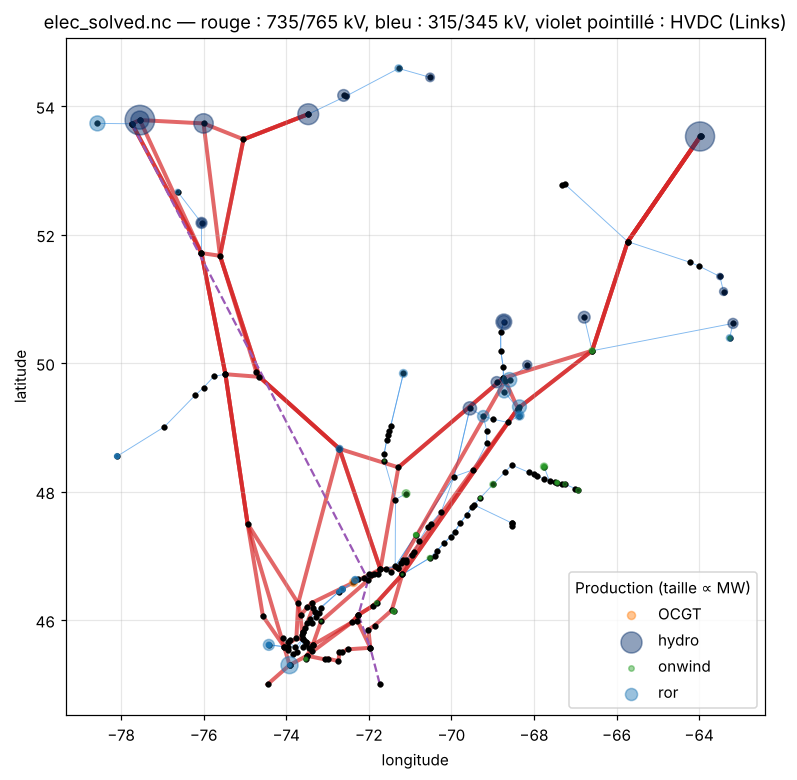

In [11]:
def carte(n, ax, couleur_bus=None, cmap="coolwarm", vmin=None, vmax=None, largeur=None, titre=""):
    xy = n.buses[["x", "y"]]
    couleurs_v = {315: "#4c9be8", 345: "#4c9be8", 450: "#9b59b6", 735: "#d62728", 765: "#d62728"}
    for i, l in n.lines.iterrows():
        (x0, y0), (x1, y1) = xy.loc[l.bus0], xy.loc[l.bus1]
        lw = 0.6 + 2 * (largeur[i] if largeur is not None else (l.v_nom >= 700))
        ax.plot([x0, x1], [y0, y1], color=couleurs_v.get(l.v_nom, "gray"), lw=lw, alpha=0.7, zorder=1)
    for i, l in n.links.iterrows():
        (x0, y0), (x1, y1) = xy.loc[l.bus0], xy.loc[l.bus1]
        ax.plot([x0, x1], [y0, y1], color="#9b59b6", lw=1.5, ls="--", zorder=1)
    sc = ax.scatter(xy.x, xy.y, c=couleur_bus if couleur_bus is not None else "k", s=14, cmap=cmap,
                    vmin=vmin, vmax=vmax, zorder=2, edgecolors="k", linewidths=0.3)
    ax.set_aspect(1 / np.cos(np.radians(50))); ax.set_title(titre); ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
    return sc

fig, ax = plt.subplots(figsize=(9, 8))
carte(s, ax, titre="elec_solved.nc — rouge : 735/765 kV, bleu : 315/345 kV, violet pointillé : HVDC (Links)")
gen = pd.concat([s.generators[s.generators.carrier.isin(["ror", "onwind", "OCGT"])][["bus", "p_nom", "carrier"]],
                 s.storage_units[["bus", "p_nom", "carrier"]]])
coul = {"ror": "#1f77b4", "hydro": "#08306b", "onwind": "#2ca02c", "OCGT": "#ff7f0e"}
for c, g in gen.groupby("carrier"):
    ax.scatter(s.buses.loc[g.bus, "x"], s.buses.loc[g.bus, "y"], s=g.p_nom / 15, alpha=0.45, color=coul[c], label=c, zorder=3)
ax.legend(title="Production (taille ∝ MW)", loc="lower right"); plt.show()

### 4.2 Les lignes : vérifier la formule des paramètres HQ

Dans `apply_hq_line_characteristics.py` : $r, x = (r, x)_{/km} \cdot L / n_{par}$ et $b = b_{/km} \cdot 10^{-6} \cdot L \cdot n_{par}$.
Un `Line` PyPSA = **un corridor** (pas un circuit) ; les circuits parallèles sont repliés dans `num_parallel`.
On vérifie que toutes les lignes ≥ 315 kV du réseau respectent bien cette formule.

In [12]:
tier = s.lines.v_nom.map({315.0: 315, 345.0: 315, 735.0: 735, 765.0: 735})
L = s.lines[tier.notna()].copy(); t = tier.dropna()
L["x_attendu"] = HQ.loc[t, "xl_ohm_per_km"].values * L.length / L.num_parallel
L["b_attendu"] = HQ.loc[t, "bc_uS_per_km"].values * 1e-6 * L.length * L.num_parallel
print(f"x / x_attendu : min {(L.x / L.x_attendu).min():.4f}, max {(L.x / L.x_attendu).max():.4f}")
print(f"b / b_attendu : min {(L.b / L.b_attendu).min():.4f}, max {(L.b / L.b_attendu).max():.4f}")
print("\nnum_parallel :", s.lines.num_parallel.value_counts().sort_index().to_dict())
s.lines[["bus0", "bus1", "v_nom", "length", "num_parallel", "r", "x", "b", "s_nom"]].sort_values("length", ascending=False).head(8)

x / x_attendu : min 1.0000, max 1.0000
b / b_attendu : min 1.0000, max 1.0000

num_parallel : {1.0: 158, 2.0: 113, 3.0: 5}


,bus0,bus1,v_nom,length,num_parallel,r,x,b,s_nom
name,,,,,,,,,
3756,651,25,735.0,622.590677,1.0,6.225907,205.454923,0.003051,4380.162996
1448,114,148,735.0,567.736705,1.0,5.677367,187.353113,0.002782,4716.222398
1049,114,148,735.0,563.370794,1.0,5.633708,185.912362,0.002761,4746.221084
2408,114,1291,735.0,500.629917,1.0,5.006299,165.207873,0.002453,5242.783677
3535,2944,286,735.0,471.427214,1.0,4.714272,155.570981,0.002310,5524.001016
162,340,457,735.0,456.561283,1.0,4.565613,150.665223,0.002237,5682.191948
161,451,345,735.0,437.213095,1.0,4.372131,144.280321,0.002142,5905.447796
880,312,308,735.0,433.409000,1.0,4.334090,143.024970,0.002124,5951.854099


### 4.3 Le parc de production

Note les deux « faux » générateurs : `load_shedding` (un par nœud de charge, 10 000 $/MWh = coût de la défaillance VOLL :
la LOPF peut délester au lieu d'être infaisable, et leur production = la charge non servie) et le `slack-placeholder`
(`p_max_pu = 0`, porte seulement le drapeau Slack sur le nœud 339, qui n'a que du stockage).

In [13]:
parc = pd.concat([
    s.generators.groupby("carrier").p_nom.agg(["count", "sum"]).assign(type="Generator"),
    s.storage_units.groupby("carrier").p_nom.agg(["count", "sum"]).assign(type="StorageUnit")])
parc.columns = ["nombre", "p_nom total (MW)", "type"]
print(parc.round(0))
print("\nSlack :", s.generators.index[s.generators.control == "Slack"].tolist())
s.generators.loc[s.generators.control == "Slack", ["bus", "carrier", "p_nom", "p_max_pu"]]

               nombre  p_nom total (MW)         type
carrier                                             
AC                  1            7722.0    Generator
OCGT                1             411.0    Generator
load_shedding     189           34967.0    Generator
onwind             33            3495.0    Generator
ror                35           13570.0    Generator
solar               3              10.0    Generator
hydro              22           28583.0  StorageUnit

Slack : ['339 slack-placeholder']


,bus,carrier,p_nom,p_max_pu
name,,,,
339 slack-placeholder,339,AC,7722.0,0.0


### 4.4 La demande : comparaison avec la vraie demande HQ

`run_lopf_main_island.py` multiplie la demande par `DEMAND_SCALE_FACTOR = 1.0653` pour coller à la moyenne réelle de la semaine
(28 870 MW). On compare au fichier `historique-demande-electricite-quebec.csv` (horodaté en heure de l'Est, −05:00).

Modèle : moyenne 28,871 MW, min 22,027, max 34,959
Réel (décalage +0 h) : moyenne 28,870 MW, corrélation 0.9787
Réel (décalage +1 h) : moyenne 28,871 MW, corrélation 0.9999


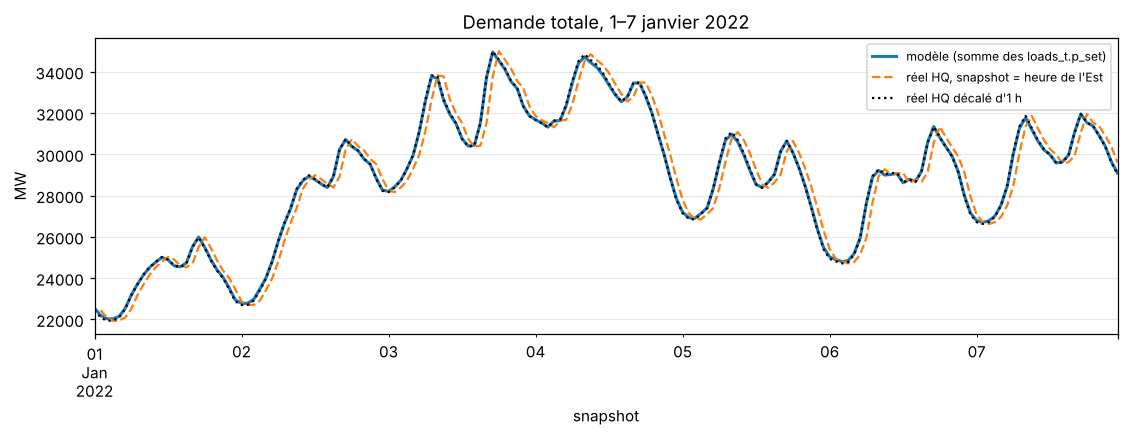

In [14]:
d_mod = s.loads_t.p_set.sum(axis=1)
h = pd.read_csv(NET / "historique-demande-electricite-quebec.csv", encoding="utf-8-sig")
h["date"] = pd.to_datetime(h["date"], utc=True)
h = h.groupby("date")["demand (MW)"].mean().sort_index()       # le fichier a quelques doublons et n'est pas trié

def reel_aligne(decalage_h):
    # snapshots du modèle (heure locale sans fuseau) + 5 h = UTC
    idx = (d_mod.index + pd.Timedelta(hours=5 + decalage_h)).tz_localize("UTC")
    return pd.Series(h.reindex(idx).values, index=d_mod.index)

print(f"Modèle : moyenne {d_mod.mean():,.0f} MW, min {d_mod.min():,.0f}, max {d_mod.max():,.0f}")
for dec in [0, 1]:
    r = reel_aligne(dec)
    print(f"Réel (décalage {dec:+d} h) : moyenne {r.mean():,.0f} MW, corrélation {d_mod.corr(r):.4f}")

fig, ax = plt.subplots(figsize=(12, 3.5))
d_mod.plot(ax=ax, label="modèle (somme des loads_t.p_set)", lw=2)
reel_aligne(0).plot(ax=ax, label="réel HQ, snapshot = heure de l'Est", ls="--")
reel_aligne(1).plot(ax=ax, label="réel HQ décalé d'1 h", ls=":", color="k")
ax.set_ylabel("MW"); ax.legend(fontsize=8); ax.set_title("Demande totale, 1–7 janvier 2022"); plt.show()

**Observation.** Avec les snapshots lus en heure de l'Est, on retrouve la corrélation de 0,979 citée dans `DATA_SOURCES.md`.
Avec un décalage d'**une heure**, la corrélation monte à ~0,9999 : la demande du modèle est en fait la série HQ, à une
convention d'horodatage près (heure de début vs heure de fin de l'intervalle). Sans conséquence pour une semaine de
simulation, mais à garder en tête si on aligne d'autres séries horaires (ex. météo, production) sur les snapshots.

### 4.5 Le résultat de la LOPF

Production moyenne par filière (MW) :
carrier
OCGT                    16.0
onwind                 690.0
ror                   4698.0
hydro (réservoir)    23466.0

Délestage total : 0.0 MWh  (0.00%)
Chargement max des lignes : 71.9%   (doc : 71,9 %)


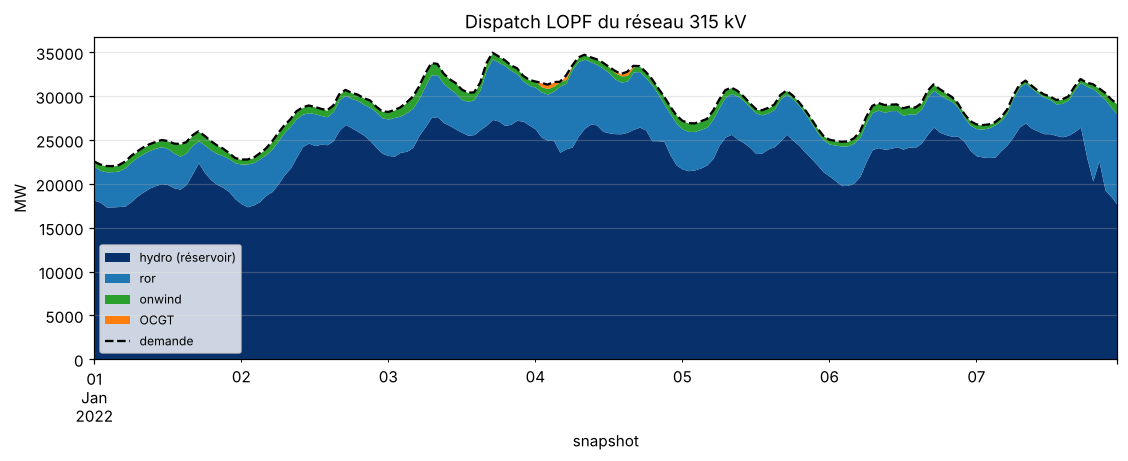

In [15]:
disp = pd.concat([s.generators_t.p.T.groupby(s.generators.carrier).sum().T,
                  s.storage_units_t.p.T.groupby(s.storage_units.carrier).sum().T.add_suffix(" (réservoir)")], axis=1)
disp = disp.loc[:, disp.abs().sum() > 1]
print("Production moyenne par filière (MW) :"); print(disp.mean().round(0).to_string())
delest = s.generators_t.p.loc[:, s.generators.carrier == "load_shedding"].sum().sum()
print(f"\nDélestage total : {delest:.1f} MWh  ({delest / d_mod.sum():.2%})")
charge_lignes = (s.lines_t.p0.abs() / s.lines.s_nom).max()
print(f"Chargement max des lignes : {charge_lignes.max():.1%}   (doc : 71,9 %)")

fig, ax = plt.subplots(figsize=(12, 3.8))
disp[["hydro (réservoir)", "ror", "onwind", "OCGT"]].clip(lower=0).plot.area(ax=ax, linewidth=0,
     color=["#08306b", "#1f77b4", "#2ca02c", "#ff7f0e"])
d_mod.plot(ax=ax, color="k", ls="--", label="demande")
ax.set_title("Dispatch LOPF du réseau 315 kV"); ax.set_ylabel("MW"); ax.legend(fontsize=8, loc="lower left"); plt.show()

### 4.6 DC power flow sur le dispatch LOPF (`run_pf.py --method lpf`)

On importe directement la fonction de Nathan qui recopie le dispatch (`p`) dans les consignes (`p_set`).

In [16]:
import run_pf
sd = s.copy()
flux_lopf = sd.lines_t.p0.copy()
with silence():
    run_pf.use_lopf_dispatch_as_setpoints(sd)
sd.lpf()
print("Écart max des flux DC PF vs LOPF :", round(float((sd.lines_t.p0 - flux_lopf).abs().max().max()), 3), "MW")
ang = np.degrees(sd.buses_t.v_ang[sd.lines.bus0].values - sd.buses_t.v_ang[sd.lines.bus1].values)
ang = pd.DataFrame(np.abs(ang), index=sd.snapshots, columns=sd.lines.index).max()
print(f"Plus grand angle aux bornes d'une ligne : {ang.max():.1f}° (ligne {ang.idxmax()}) ; lignes > 30° : {(ang > 30).sum()}")
print("(doc : 59,2° sur la ligne 3360, 17 lignes > 30°)")

Écart max des flux DC PF vs LOPF : 0.0 MW
Plus grand angle aux bornes d'une ligne : 59.2° (ligne 3360) ; lignes > 30° : 17
(doc : 59,2° sur la ligne 3360, 17 lignes > 30°)


Un angle de 59° aux bornes d'une ligne est très loin de ce qu'un vrai réseau tolère (~30°). La LOPF ne le voit pas (elle n'a
pas de limite d'angle) ; l'AC PF, lui, va échouer. C'est l'indice qu'il manque des circuits / de la compensation.

---
# Partie 5 — `run_pf.py` : préparer un AC power flow

Les données sources n'ont **aucune** information réactive. `prepare_for_ac_pf()` comble les trous avec des hypothèses
documentées :

1. transformateurs : `r = x / 30` (X/R générique) ;
2. charges : `q_set = p_set · tan(acos 0,95)` ;
3. générateurs PQ : `q_set = p_nom · tan(acos 0,9)` (lié à la puissance installée, pas au dispatch) ;
4. placeholders sur les nœuds stockage-seul, puis classement **PV** des nœuds assez gros et dominés par la production
   (`--pv-min-capacity`, `--pv-max-load-ratio` : 100 MW / 10 % pour le 315 kV, 0 / 1 pour le 735 kV) ;
5. bornes 0,95–1,05 pu (informatives : `n.pf()` ne les impose pas) ; et **remise du Slack** après le reset PQ/PV.

Puis : `n.lpf()` pour une bonne initialisation, et `n.pf(use_seed=True)`.

### 5.1 Le 315 kV ne converge pas

⏱️ Cette cellule prend ~3 minutes : Newton-Raphson épuise ses itérations sur chaque heure qui diverge.

In [17]:
s_ac = s.copy()
with silence():
    run_pf.use_lopf_dispatch_as_setpoints(s_ac)
    s_ac.calculate_dependent_values(); s_ac.determine_network_topology()
    run_pf.prepare_for_ac_pf(s_ac)          # seuils par défaut = ceux du 315 kV
print("Types de générateurs :", s_ac.generators.control.value_counts().to_dict())
print("Slacks :", s_ac.generators.index[s_ac.generators.control == "Slack"].tolist())
print("  -> 1 vrai slack (339) + 1 slack par terminal HVDC sans ligne AC : chacun est un sous-réseau à 1 nœud, où PyPSA\n"
      "     prend le générateur disponible (ici le load_shedding) ou le placeholder à 0 MW ajouté par run_pf.py")
t0 = time.time()
s_ac.lpf(); res = s_ac.pf(use_seed=True)
conv = res.converged.all(axis=1)
print(f"AC PF 315 kV : {conv.sum()} / {len(conv)} heures convergées ({time.time()-t0:.0f} s)   (doc : 1/168)")
print("Heure(s) convergée(s) :", list(conv.index[conv]))

Types de générateurs : {'PQ': 245, 'PV': 26, 'Slack': 6}
Slacks : ['1015 load_shedding', '161 load_shedding', '3549 load_shedding', '2206 load_shedding', '339 slack-placeholder', '65 pf-slack-placeholder']
  -> 1 vrai slack (339) + 1 slack par terminal HVDC sans ligne AC : chacun est un sous-réseau à 1 nœud, où PyPSA
     prend le générateur disponible (ici le load_shedding) ou le placeholder à 0 MW ajouté par run_pf.py


AC PF 315 kV : 1 / 168 heures convergées (170 s)   (doc : 1/168)
Heure(s) convergée(s) : [Timestamp('2022-01-07 19:00:00')]


Nathan localise deux zones de divergence : les longs corridors 735 kV non corrigés (mêmes angles > 30° qu'au §4.6) et
un **éperon radial de nœuds 315 kV** (240, 1548, 1762, 1772, 2207, 3719, 1693, 3836, 2812). C'est le principal chantier
ouvert : appliquer les corrections de corridors **avant** la LOPF 315 kV.

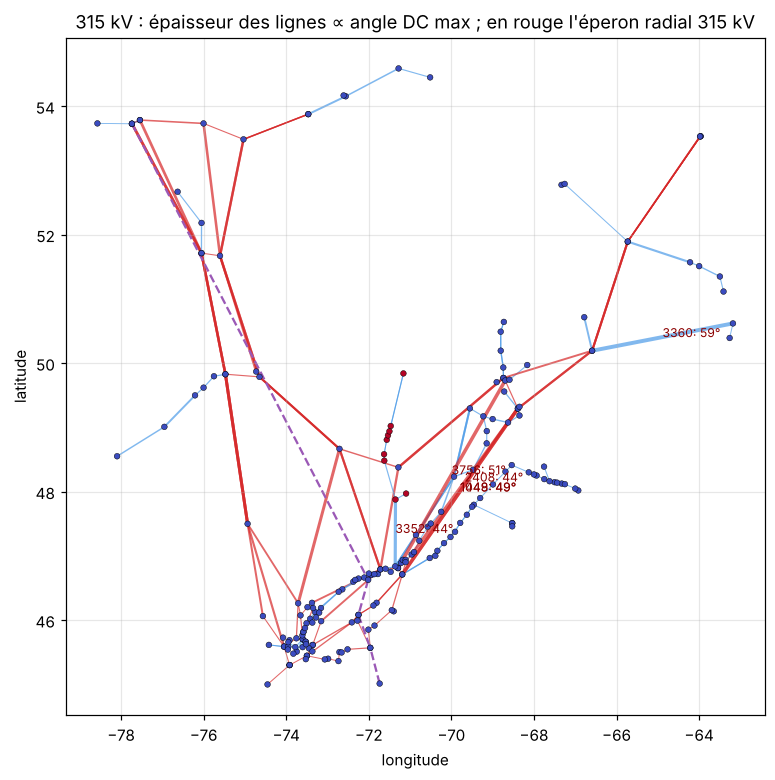

In [18]:
fig, ax = plt.subplots(figsize=(9, 8))
eperon = ["240", "1548", "1762", "1772", "2207", "3719", "1693", "3836", "2812"]
coul = np.where(s.buses.index.isin(eperon), 1.0, 0.0)
carte(s, ax, couleur_bus=coul, cmap="coolwarm", largeur=(ang / 60).clip(upper=1),
      titre="315 kV : épaisseur des lignes ∝ angle DC max ; en rouge l'éperon radial 315 kV")
top = ang.sort_values(ascending=False).head(6)
for l in top.index:
    b0, b1 = s.lines.loc[l, ["bus0", "bus1"]]
    ax.annotate(f"{l}: {top[l]:.0f}°", s.buses.loc[[b0, b1], ["x", "y"]].mean(), fontsize=8, color="darkred")
plt.show()

---
# Partie 6 — `reduce_to_735kv.py` : réduire au squelette 735 kV

Méthode : on garde les nœuds 735/765 kV (765 relabellisé 735). Chaque autre nœud est rattaché au nœud 735 kV **le plus proche
en longueur de ligne réelle** (Dijkstra multi-sources sur le graphe lignes + transfos + liens), puis charges et générateurs
sont sommés par (nœud cible, filière). Le dispatch LOPF est **conservé** en `p_set` : ce réseau n'est jamais ré-optimisé.

Pourquoi pas « le plus proche à vol d'oiseau » (comme `reduce_voltage_network.py`) ? Comparons les deux sur `elec_solved.nc` :

In [19]:
from reduce_to_735kv import build_full_graph, BACKBONE_VOLTAGES
G = build_full_graph(s)
squelette = set(s.buses.index[s.buses.v_nom.isin(BACKBONE_VOLTAGES)])
dist, chemins = nx.multi_source_dijkstra(G, sources=squelette, weight="length")
par_graphe = pd.Series({b: chemins[b][0] for b in s.buses.index if b in chemins})

# à vol d'oiseau (haversine)
sq = s.buses.loc[sorted(squelette), ["x", "y"]]
def plus_proche_vol_oiseau(b):
    lon, lat = np.radians(s.buses.loc[b, ["x", "y"]].astype(float))
    lo2, la2 = np.radians(sq.x.values), np.radians(sq.y.values)
    d = 2 * 6371 * np.arcsin(np.sqrt(np.sin((la2 - lat) / 2) ** 2 + np.cos(lat) * np.cos(la2) * np.sin((lo2 - lon) / 2) ** 2))
    return sq.index[d.argmin()]
par_vol = pd.Series({b: plus_proche_vol_oiseau(b) for b in par_graphe.index})

autres = par_graphe.index.difference(list(squelette))
diff = autres[par_graphe[autres] != par_vol[autres]]
charge_moy = s.loads_t.p_set.mean().groupby(s.loads.bus).sum()
print(f"{len(squelette)} nœuds 735/765 kV ; {len(autres)} autres nœuds à rattacher")
print(f"Les deux méthodes divergent pour {len(diff)} nœuds, portant {charge_moy.reindex(diff).fillna(0).sum():,.0f} MW de charge moyenne")
pd.DataFrame({"par graphe": par_graphe[diff], "km de ligne": pd.Series(dist)[diff].round(0),
              "à vol d'oiseau": par_vol[diff], "charge (MW)": charge_moy.reindex(diff).fillna(0).round(0)}
             ).sort_values("charge (MW)", ascending=False).head(10)

58 nœuds 735/765 kV ; 147 autres nœuds à rattacher
Les deux méthodes divergent pour 72 nœuds, portant 14,687 MW de charge moyenne


,par graphe,km de ligne,à vol d'oiseau,charge (MW)
263,195,25.0,2,3618.0
45,195,12.0,677,2808.0
800,195,32.0,133,2496.0
271,195,15.0,603,970.0
3836,25,195.0,150,486.0
186,25,242.0,1291,374.0
2812,25,233.0,150,369.0
2811,25,122.0,1291,310.0
178,148,89.0,1291,301.0
2842,2,12.0,43,242.0


In [20]:
r735 = pypsa.Network(CUR / "elec_735kv.nc")
print(pd.Series({c: len(getattr(r735, c)) for c in composants}, name="elec_735kv.nc").to_string())
print(f"\nDemande moyenne : 315 kV {s.loads_t.p_set.sum(axis=1).mean():,.0f} MW  →  735 kV {r735.loads_t.p_set.sum(axis=1).mean():,.0f} MW")
print("Demande conservée en entier : les charges des terminaux HVDC du sud sont rattachées au squelette *à travers* le Link\n"
      "(inclus dans le graphe de Dijkstra), même si le Link lui-même est supprimé du réseau 735 kV.")
print("Slack :", r735.generators.index[r735.generators.control == "Slack"].tolist())

buses                58
lines               109
links                 0
transformers          0
loads                58
generators           82
storage_units        11
shunt_impedances      0

Demande moyenne : 315 kV 28,871 MW  →  735 kV 28,871 MW
Demande conservée en entier : les charges des terminaux HVDC du sud sont rattachées au squelette *à travers* le Link
(inclus dans le graphe de Dijkstra), même si le Link lui-même est supprimé du réseau 735 kV.
Slack : ['114 ror']


---
# Partie 7 — Les deux corrections décisives du 735 kV

### 7.1 Nombre de circuits (`correct_sending_end_circuits.py`)

OSM ne code pas fiablement les circuits parallèles. Cinq corridors sortant des grandes centrales étaient à 1–2 circuits au lieu
de 3. Le script fixe `num_parallel` (3,0 sur un `Line` unique, 1,5 + 1,5 quand OSM a déjà 2 objets) et recalcule r/x/b avec la
formule HQ. Dans `elec_735kv.nc` c'est déjà appliqué :

In [21]:
from correct_sending_end_circuits import NEW_NUM_PARALLEL
from apply_series_compensation import TARGET_LINES, apply_compensation
t = r735.lines.loc[list(NEW_NUM_PARALLEL), ["bus0", "bus1", "length", "num_parallel", "x", "s_nom"]].copy()
t["x sans compensation"] = HQ.loc[735, "xl_ohm_per_km"] * t.length / t.num_parallel
t["compensée ?"] = t.index.isin(list(TARGET_LINES))
t.round(1)

,bus0,bus1,length,num_parallel,x,s_nom,x sans compensation,compensée ?
name,,,,,,,,
2408,114,1291,500.6,3.0,16.5,15728.4,55.1,True
162,340,457,456.6,3.0,15.1,17046.6,50.2,True
3756,651,25,622.6,3.0,68.5,13140.5,68.5,False
1049,114,148,563.4,1.5,37.2,7119.3,123.9,True
1448,114,148,567.7,1.5,37.5,7074.3,124.9,True
156,66,457,432.7,1.5,28.6,8941.4,95.2,True
1938,66,457,432.7,1.5,28.6,8941.4,95.2,True


### 7.2 Compensation série (`apply_series_compensation.py`)

$x = x_{/km}\cdot L / n_{par}\cdot(1-k)$ sur 15 lignes : les 10 longues lignes qui alimentent les nœuds d'effondrement 308, 1291,
312 (trouvés par `continuation_pf.py`) et les 5 lignes aux plus grands angles DC. Le calcul part toujours du x non compensé :
relancer le script ne cumule pas.

On rejoue le tableau de `POWER_FLOW.md` en appelant la fonction de Nathan avec `k = 0`, `0,5`, `0,7` :

In [22]:
def ac_pf(net, pv_min=0, pv_ratio=1):
    # Prépare (hypothèses de run_pf.py) puis AC PF sur les 168 h. Renvoie (réseau résolu, série de convergence).
    m = net.copy()
    with silence():
        m.calculate_dependent_values(); m.determine_network_topology()
        run_pf.prepare_for_ac_pf(m, pv_min_capacity=pv_min, pv_max_load_ratio=pv_ratio)
        m.lpf(m.snapshots); res = m.pf(m.snapshots, use_seed=True)
    return m, res.converged.all(axis=1)

lignes = []
resultats = {}
for k in [0.0, 0.3, 0.5, 0.7]:
    net = r735.copy()
    with silence():
        apply_compensation(net, fraction=k)
    m, c = ac_pf(net)
    v = m.buses_t.v_mag_pu.loc[c]
    lignes.append({"compensation": f"{k:.0%}", "heures convergées": f"{c.sum()}/168",
                   "V min (pu)": round(v.min().min(), 3), "V max (pu)": round(v.max().max(), 3),
                   "nœuds < 0,95": int((v.min() < 0.95).sum()), "nœuds > 1,05": int((v.max() > 1.05).sum())})
    resultats[k] = (m, c)
pd.DataFrame(lignes)

,compensation,heures convergées,V min (pu),V max (pu),"nœuds < 0,95","nœuds > 1,05"
0,0%,110/168,0.791,1.152,23,17
1,30%,168/168,0.798,1.133,25,17
2,50%,168/168,0.888,1.125,19,17
3,70%,168/168,0.904,1.123,14,14


On retrouve exactement la doc : **110/168 sans compensation** (0,791–1,152 pu), **168/168 à 50 % et 70 %** (0,904–1,123 pu à 70 %).
Les heures qui échouent sans compensation sont les heures de forte demande :

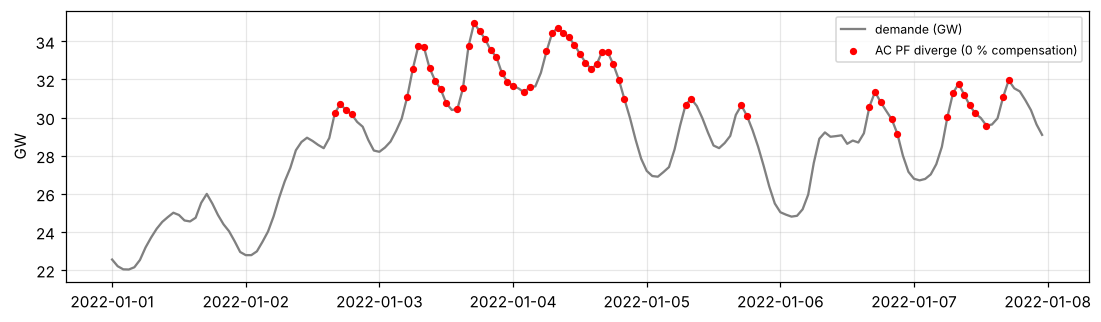

Demande des heures qui divergent : 29.2–35.0 GW (doc : 29,2–35,0 GW)


In [23]:
m0, c0 = resultats[0.0]
dem = r735.loads_t.p_set.sum(axis=1) / 1000
fig, ax = plt.subplots(figsize=(12, 3.2))
ax.plot(dem.index, dem, color="gray", label="demande (GW)")
ax.scatter(dem.index[~c0], dem[~c0], color="red", s=14, zorder=3, label="AC PF diverge (0 % compensation)")
ax.set_ylabel("GW"); ax.legend(fontsize=8); plt.show()
print(f"Demande des heures qui divergent : {dem[~c0].min():.1f}–{dem[~c0].max():.1f} GW (doc : 29,2–35,0 GW)")

---
# Partie 8 — Shunts : condensateurs et réactances (`add_shunt_impedance.py`)

Avec la compensation série, tout converge mais 14 nœuds sont sous 0,95 pu et 14 au-dessus de 1,05 pu. La méthode de Nathan :

1. AC PF, liste des nœuds hors bande ;
2. **sonde** : un générateur PV à P = 0 à chacun de ces nœuds, tenu à la borne violée (1,05 ou 0,95) → son Q horaire = le
   réactif nécessaire (tous en même temps, pour capter les interactions entre voisins) ;
3. on ignore les nœuds hors bande dans les deux sens (un appareil fixe ne corrige qu'un sens) ;
4. $b = \text{échelle}\cdot Q_{pire\ heure}/V_{nom}^2$ : réactances 100 %, condensateurs 70 %.

Dans PyPSA, `ShuntImpedance` : $Q = V_{pu}^2 \cdot b_{pu}$ ; `b > 0` condensateur, `b < 0` réactance ; `b` n'a **pas** de
dimension temporelle.

In [24]:
sh = pypsa.Network(CUR / "elec_735kv_shunt.nc")
tab = sh.shunt_impedances[["bus", "b"]].copy()
tab["Q à 1 pu (MVAr)"] = (tab.b * sh.buses.loc[tab.bus, "v_nom"].values ** 2).round(0)
tab["type"] = np.where(tab.b > 0, "condensateur", "réactance")
print(tab.groupby("type")["Q à 1 pu (MVAr)"].agg(["count", "sum"]), "\n(doc : 5 condensateurs +3 769, 11 réactances −6 106)")
tab.sort_values("Q à 1 pu (MVAr)")

              count     sum
type                       
condensateur      5  3768.0
réactance        11 -6106.0 
(doc : 5 condensateurs +3 769, 11 réactances −6 106)


,bus,b,Q à 1 pu (MVAr),type
name,,,,
310 shunt-reactor,310,-0.003005,-1623.0,réactance
345 shunt-reactor,345,-0.001883,-1017.0,réactance
469 shunt-reactor,469,-0.001653,-893.0,réactance
3319 shunt-reactor,3319,-0.000959,-518.0,réactance
150 shunt-reactor,150,-0.000825,-446.0,réactance
25 shunt-reactor,25,-0.000773,-418.0,réactance
148 shunt-reactor,148,-0.000685,-370.0,réactance
312 shunt-reactor,312,-0.000648,-350.0,réactance
1291 shunt-reactor,1291,-0.000450,-243.0,réactance


Avec shunts : 168/168 convergées, V = 0.966–1.059 pu, nœuds > 1,05 : 15, heures en surtension : 16
(doc : 168/168, 0,966–1,059 pu, 15 nœuds, 16 heures)


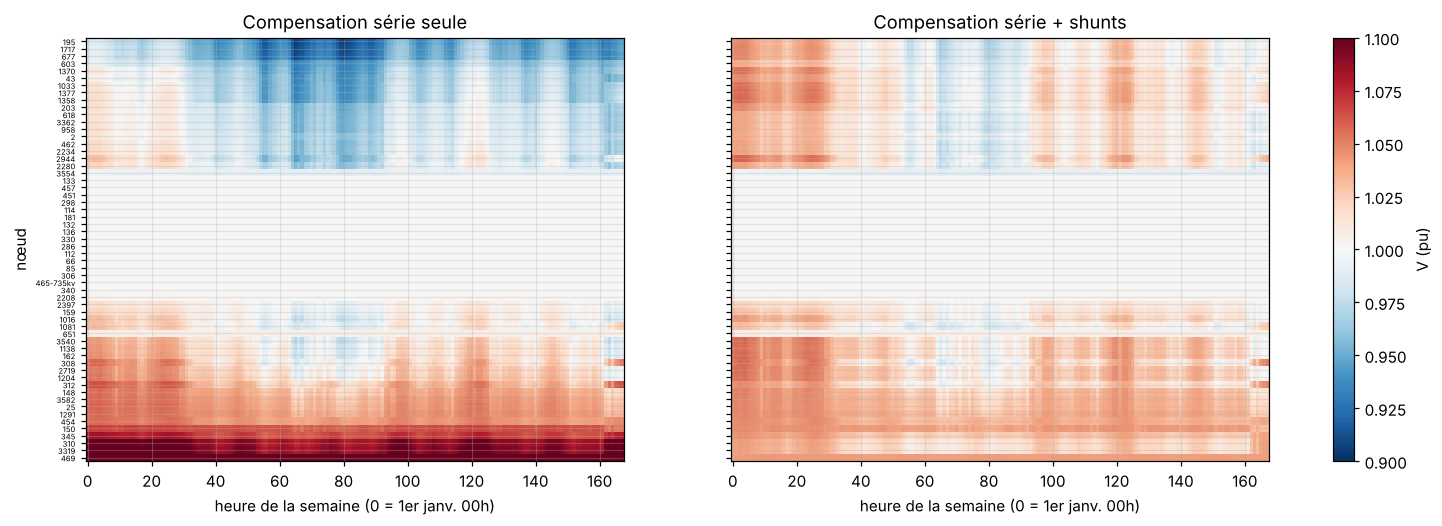

In [25]:
msh, csh = ac_pf(sh)
vsh = msh.buses_t.v_mag_pu
m70, c70 = resultats[0.7]
v70 = m70.buses_t.v_mag_pu
print(f"Avec shunts : {csh.sum()}/168 convergées, V = {vsh.min().min():.3f}–{vsh.max().max():.3f} pu, "
      f"nœuds > 1,05 : {(vsh.max() > 1.05).sum()}, heures en surtension : {(vsh > 1.05).any(axis=1).sum()}")
print("(doc : 168/168, 0,966–1,059 pu, 15 nœuds, 16 heures)")

fig, ax = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
ordre = v70.mean().sort_values().index
for a, v, titre in [(ax[0], v70, "Compensation série seule"), (ax[1], vsh, "Compensation série + shunts")]:
    im = a.imshow(v[ordre].T.values, aspect="auto", cmap="RdBu_r", vmin=0.9, vmax=1.1)
    a.set_title(titre); a.set_xlabel("heure de la semaine (0 = 1er janv. 00h)")
ax[0].set_yticks(range(len(ordre))); ax[0].set_yticklabels(ordre, fontsize=5); ax[0].set_ylabel("nœud")
plt.colorbar(im, ax=ax, label="V (pu)", fraction=0.025); plt.show()

Les bandes rouges restantes à droite sont les heures de nuit (00h–03h), demande la plus faible : la surtension due au
*charging* des lignes (§2.2) que des shunts **fixes** ne peuvent pas suivre.

### 8.1 Le réactif « gratuit » des nœuds PV

Rappel (§1.3) : un générateur PV de PyPSA n'a **aucune limite de Q**. Regardons ce que les nœuds PV fournissent / absorbent
réellement pour tenir leur consigne de 1,00 pu, la nuit (faible demande) et à la pointe :

In [26]:
pv = msh.generators.index[msh.generators.control.isin(["PV", "Slack"])]
creuse = sh.loads_t.p_set.sum(axis=1).idxmin(); pointe_h = sh.loads_t.p_set.sum(axis=1).idxmax()
Qpv = pd.DataFrame({f"creux {creuse:%d/%m %Hh}": msh.generators_t.q.loc[creuse, pv],
                    f"pointe {pointe_h:%d/%m %Hh}": msh.generators_t.q.loc[pointe_h, pv],
                    "bus": msh.generators.loc[pv, "bus"]})
# capacité installée totale au nœud (générateurs réels + réservoirs, sans placeholders ni délestage)
reels = msh.generators[~msh.generators.index.str.contains("placeholder") & (msh.generators.carrier != "load_shedding")]
cap_bus = reels.groupby("bus").p_nom.sum().add(msh.storage_units.groupby("bus").p_nom.sum(), fill_value=0)
Qpv["capacité au nœud (MW)"] = Qpv.bus.map(cap_bus)
Qpv["≈ |Q| d'une machine réelle à fp 0,9 (MVAr)"] = Qpv["capacité au nœud (MW)"] * np.tan(np.arccos(0.9))
print("Q > 0 : production de réactif ; Q < 0 : absorption")
Qpv.drop(columns="bus").round(0).sort_values(Qpv.columns[0])

Q > 0 : production de réactif ; Q < 0 : absorption


,creux 01/01 03h,pointe 03/01 17h,capacité au nœud (MW),"≈ |Q| d'une machine réelle à fp 0,9 (MVAr)"
name,,,,
457 ror,-8044.0,-3686.0,1398.0,677.0
114 ror,-7853.0,-4532.0,5167.0,2502.0
112 ror,-4283.0,-3127.0,5348.0,2590.0
181 ror,-4204.0,-1209.0,1846.0,894.0
286 ror,-4107.0,-2763.0,519.0,251.0
306 storage-pv-placeholder,-3664.0,-2594.0,640.0,310.0
136 ror,-3446.0,2000.0,1581.0,766.0
340 AC,-2356.0,-2205.0,15444.0,7480.0
298 ror,-1926.0,-1281.0,4445.0,2153.0


**Lecture.** Presque tous les nœuds PV **absorbent** plusieurs GVAr — même à la pointe — souvent bien plus que ce qu'une machine
de cette taille pourrait faire (dernière colonne, ordre de grandeur). Le 735 kV est en **excédent de réactif** : charging des longues
lignes, condensateurs shunt, et surtout l'hypothèse de `run_pf.py` qui fait injecter à chaque générateur PQ un Q **fixe**
$p_{nom}\tan(\arccos 0{,}9)$ à toute heure. Les PV, au réactif illimité, épongent le surplus pour tenir 1,00 pu.
(`COMPONENTS.md` parle de nœuds 114 et 457 qui *fournissent* plusieurs GVAr ; ici ils en *absorbent* — même conclusion, Q
irréaliste, signe opposé.) C'est cohérent avec le §10 : avec des limites Q, pandapower ne converge plus.

---
# Partie 9 — Résultats sur carte et analyse N-1 dans PyPSA

### 9.1 Heure de pointe sur le 735 kV avec shunts

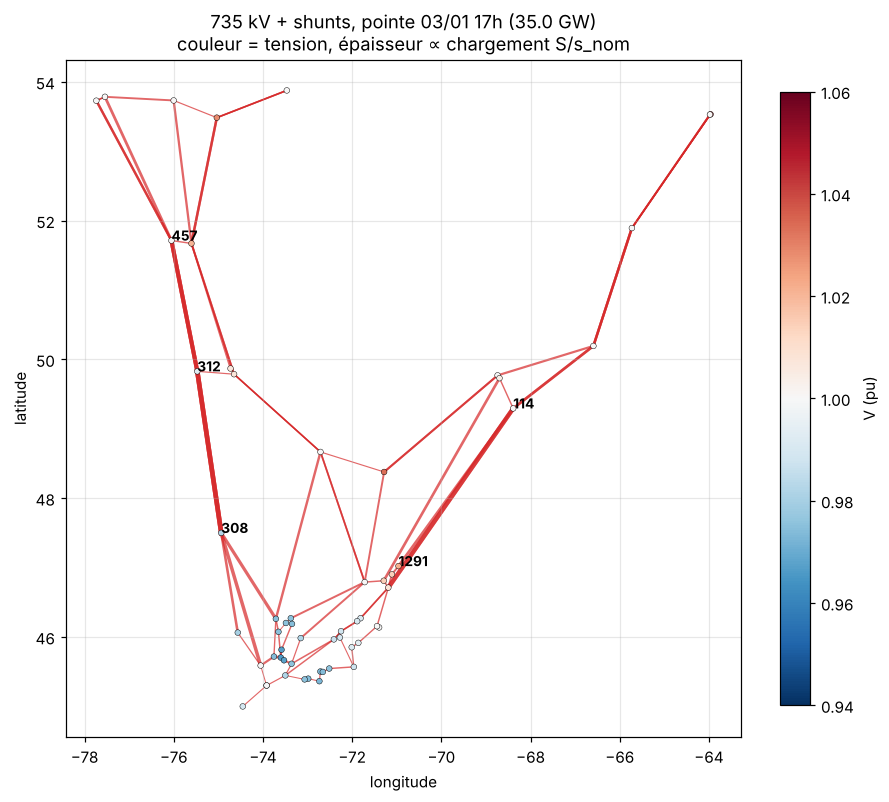

Lignes les plus chargées à la pointe :
       de vers  S/s_nom
name                   
1935  312  308    0.606
2410  312  308    0.606
880   312  308    0.603
1049  114  148    0.551
1448  114  148    0.551


In [27]:
pointe = sh.loads_t.p_set.sum(axis=1).idxmax()
S_ligne = np.sqrt(msh.lines_t.p0 ** 2 + msh.lines_t.q0 ** 2)
charge_pct = (S_ligne.loc[pointe] / msh.lines.s_nom)
fig, ax = plt.subplots(figsize=(9, 8))
sc = carte(msh, ax, couleur_bus=vsh.loc[pointe], cmap="RdBu_r", vmin=0.94, vmax=1.06,
           largeur=charge_pct.clip(upper=1) * 2,
           titre=f"735 kV + shunts, pointe {pointe:%d/%m %Hh} ({sh.loads_t.p_set.sum(axis=1)[pointe]/1000:.1f} GW)\n"
                 "couleur = tension, épaisseur ∝ chargement S/s_nom")
plt.colorbar(sc, ax=ax, label="V (pu)", fraction=0.04)
for b in ["114", "308", "1291", "312", "457"]:
    ax.annotate(b, msh.buses.loc[b, ["x", "y"]], fontsize=9, fontweight="bold")
plt.show()
print("Lignes les plus chargées à la pointe :")
print(pd.DataFrame({"de": msh.lines.bus0, "vers": msh.lines.bus1, "S/s_nom": charge_pct.round(3)}).sort_values("S/s_nom", ascending=False).head(5))

### 9.2 Analyse N-1 en AC, directement dans PyPSA

Même logique que ton `n1_contingency.py` (pandapower sur le `.m`), mais sur le réseau PyPSA lui-même, à l'heure de pointe :
on retire chaque ligne une à une, on relance l'AC PF, on classe. Une ligne dont la perte coupe le réseau en deux est marquée
« îlotage » (détecté avec networkx). On retire / remet la ligne plutôt que de copier le réseau à chaque fois. ⏱️ ~2 minutes.

In [28]:
base = sh.copy()
with silence():
    base.calculate_dependent_values(); base.determine_network_topology()
    run_pf.prepare_for_ac_pf(base, pv_min_capacity=0, pv_max_load_ratio=1)
base.set_snapshots([pointe])
base.lpf(); base.pf(use_seed=True)
print(f"Cas de base : V min {base.buses_t.v_mag_pu.min().min():.3f} pu")

Gm = nx.MultiGraph()
Gm.add_edges_from((r.bus0, r.bus1, i) for i, r in base.lines.iterrows())
attrs = ["bus0", "bus1", "r", "x", "b", "s_nom", "length", "num_parallel"]
t0, lignes = time.time(), []
for l in list(base.lines.index):
    row = base.lines.loc[l, attrs].to_dict()
    H = Gm.copy(); H.remove_edge(row["bus0"], row["bus1"], l)
    if not nx.is_connected(H):
        lignes.append({"ligne": l, "de": row["bus0"], "vers": row["bus1"], "état": "ÎLOTAGE"}); continue
    base.remove("Line", l)
    try:
        base.lpf(); ok = bool(base.pf(use_seed=True).converged.values.all())
    except Exception:
        ok = False
    v = base.buses_t.v_mag_pu.iloc[0]
    S = np.sqrt(base.lines_t.p0 ** 2 + base.lines_t.q0 ** 2).iloc[0] / base.lines.s_nom
    lignes.append({"ligne": l, "de": row["bus0"], "vers": row["bus1"], "km": round(row["length"]),
                   "état": "converge" if ok else "EFFONDREMENT",
                   "V min": v.min() if ok else np.nan, "nœuds hors bande": int(((v < 0.95) | (v > 1.05)).sum()) if ok else np.nan,
                   "S/s_nom max": S.max() if ok else np.nan})
    base.add("Line", l, **row)
n1 = pd.DataFrame(lignes)
n1["rang"] = n1["état"].map({"EFFONDREMENT": 0, "ÎLOTAGE": 1, "converge": 2})
n1 = n1.sort_values(["rang", "V min"]).drop(columns="rang")
print(f"{len(n1)} contingences en {time.time()-t0:.0f} s :", n1["état"].value_counts().to_dict())
n1.head(12).round(3)

Cas de base : V min 0.966 pu


109 contingences en 107 s : {'converge': 105, 'EFFONDREMENT': 2, 'ÎLOTAGE': 2}


,ligne,de,vers,état,km,V min,nœuds hors bande,S/s_nom max
87,3534,195,603,EFFONDREMENT,14.0,NaN,NaN,NaN
102,4346,603,136,EFFONDREMENT,36.0,NaN,NaN,NaN
0,1,133,3554,ÎLOTAGE,NaN,NaN,NaN,NaN
108,bridge_132_133,132,133,ÎLOTAGE,NaN,NaN,NaN,NaN
14,440,43,677,converge,22.0,0.891,9.0,0.638
3,117,2,3362,converge,47.0,0.910,6.0,0.605
76,2524,2280,1016,converge,73.0,0.931,6.0,0.614
57,1936,308,136,converge,348.0,0.938,9.0,0.578
56,1935,312,308,converge,410.0,0.945,1.0,0.862
72,2410,312,308,converge,410.0,0.945,1.0,0.862


**Lecture.** Résultat un peu inattendu : les deux contingences qui font **effondrer** l'AC PF ne sont pas les grands corridors
du Nord mais deux lignes **courtes** de la boucle de Montréal (195–603 et 603–136, 14 et 36 km), et les tensions post-contingence
les plus basses sont aussi autour de Montréal (43–677, 2–3362…). Le nœud 195 concentre beaucoup de charge (les nœuds rattachés
par la réduction, §6) et porte le plus gros condensateur shunt (+3 096 MVAr, §8) : il dépend fortement du réactif local et de ses
quelques liaisons. Côté **surcharge**, ce sont les corridors 312–308 (3 circuits parallèles compensés) : en perdre un charge les
deux autres à ~86 %. Les deux « îlotages » sont la petite antenne 133–3554 et la liaison 735/765 kV `bridge_132_133`.

Garde en tête les biais : réactif illimité aux nœuds PV (résultats optimistes), `s_nom` = St Clair × 3 (chargements sous-estimés),
dispatch figé (en réalité les centrales se redistribueraient), et l'agrégation de la demande sur 58 nœuds (le pic à 195 vient en
partie de la réduction elle-même) — à confronter au 315 kV dès qu'il converge.

PyPSA a aussi une N-1 **DC** native, très rapide (flux seulement, pas de tensions) :

In [29]:
dc = sh.copy(); dc.set_snapshots([pointe])
with silence():
    run_pf.use_lopf_dispatch_as_setpoints(dc)
non_ilotantes = n1.loc[n1["état"] != "ÎLOTAGE", "ligne"].tolist()
flux = dc.lpf_contingency(snapshots=pointe, branch_outages=non_ilotantes)
charge_post = flux.abs().div(dc.lines.s_nom.values, axis=0).max()
print("Pire chargement DC après contingence (|P|/s_nom) :")
charge_post.drop("base").sort_values(ascending=False).head(5).round(3)

Pire chargement DC après contingence (|P|/s_nom) :


(Line, 1935)    0.884
(Line, 2410)    0.884
(Line, 880)     0.863
(Line, 1655)    0.734
(Line, 163)     0.734
dtype: float64

---
# Partie 10 — Lien avec tes scripts `Jean_tests`

Tes scripts (`Power_flow_test.py`, `visu_reseau.py`, `n1_contingency.py`) lisent `network/quebec_735kv.m`, l'export MATPOWER
de `elec_735kv_shunt.nc` fait par `export_to_matpower.py`, **à une seule heure** (la plus chargée). Points à savoir sur cet
export :

- PyPSA met les lignes en per-unit sur **1 MVA** et les transfos sur **leur propre `s_nom`** ; le script ramène tout sur la base
  MATPOWER (100 MVA) ;
- les shunts deviennent la colonne `Bs` des nœuds ;
- MATPOWER exige des limites Q : l'export met ±tan(acos 0,85)·Pmax (générique). pandapower **sait** imposer ces limites
  (`enforce_q_lims=True`, désactivé par défaut et dans tes scripts), contrairement à `n.pf()` de PyPSA — un moyen direct de
  tester l'effet du réactif illimité du §8.1.

Comparaison rapide PyPSA ↔ pandapower (sautée si pandapower n'est pas installé dans ce noyau) :

In [30]:
try:
    import pandapower as pp
    from pandapower.converter.pypower import from_ppc
    import re
    def lire_mpc(chemin):                           # même parseur que tes scripts
        txt = open(chemin).read()
        mpc = {"version": "2", "baseMVA": float(re.search(r"mpc\.baseMVA\s*=\s*([\d.]+)", txt).group(1))}
        for nom in ["bus", "gen", "branch"]:
            bloc = re.search(r"mpc\.%s\s*=\s*\[(.*?)\];" % nom, txt, re.S).group(1)
            rows = [[float(x) for x in l.split("%")[0].strip().rstrip(";").split()]
                    for l in bloc.split("\n") if l.split("%")[0].strip().rstrip(";").strip()]
            mpc[nom] = np.array(rows)
        return mpc
    net = from_ppc(lire_mpc(NET / "quebec_735kv.m"), f_hz=60)
    pp.runpp(net, numba=False)   # comme Power_flow_test.py
    print(f"pandapower (sans limites Q) : V {net.res_bus.vm_pu.min():.3f}–{net.res_bus.vm_pu.max():.3f} pu, "
          f"pertes {net.res_line.pl_mw.sum():,.0f} MW")
    try:
        pp.runpp(net, numba=False, enforce_q_lims=True, max_iteration=30)
        print(f"pandapower (AVEC limites Q) : V {net.res_bus.vm_pu.min():.3f}–{net.res_bus.vm_pu.max():.3f} pu")
    except Exception as e:
        print("pandapower avec limites Q : ne converge pas ->", type(e).__name__)
    pertes_pypsa = float((msh.lines_t.p0 + msh.lines_t.p1).sum(axis=1).max())
    print(f"PyPSA, toutes heures : V {vsh.min().min():.3f}–{vsh.max().max():.3f} pu, pertes max {pertes_pypsa:,.0f} MW")
except ImportError:
    print("pandapower absent de ce noyau (il est dans pp-env) : partie sautée.")
except Exception as e:
    print("pandapower n'a pas pu lire/résoudre le cas :", type(e).__name__, e)

INFO:pandapower.plotting.plotly.draw_layers:Failed to import plotly - interactive plotting will not be available


pandapower (sans limites Q) : V 0.963–1.042 pu, pertes 1,704 MW


pandapower avec limites Q : ne converge pas -> LoadflowNotConverged
PyPSA, toutes heures : V 0.966–1.059 pu, pertes max 1,697 MW


---
# Partie 11 — Limites connues et pistes de travail

Tirées de `network/docs/ASSUMPTIONS_AND_LIMITATIONS.md`, avec ce que ce notebook permet de tester :

| Limite | Impact | Piste |
|---|---|---|
| Pas de limites Q sur les générateurs PV dans `n.pf()` | tensions optimistes (114 et 457 fournissent plusieurs GVAr à 1,00 pu) | itérer : bascule PV→PQ quand Q dépasse une courbe de capabilité ; ou cross-check pandapower `enforce_q_lims=True` (§10) |
| Shunts fixes | 15 nœuds > 1,05 pu pendant 16 h de nuit | shunts commutés : un `b` par plage horaire (réseau par heure) ou SVC = générateur PV à P = 0 avec Q borné |
| `s_nom` = St Clair × 3 | % de chargement sous-estimés (~80 % au lieu de 60 % avec la limite thermique HQ) | `network/networks_test_hq_cold_735/` ; ou `min(thermique HQ, V² sin30°/x_compensé)` |
| Le 315 kV ne converge pas (1/168) | pas de contingence représentative à 315 kV | appliquer circuits + compensation **avant** la LOPF 315 kV ; traiter l'éperon radial (§5) |
| Réduction à vol d'oiseau dans `reduce_voltage_network.py` | demande parfois rattachée au mauvais nœud (§6) | testé par Nathan et annulé : plus juste mais converge moins bien — à retester après les corrections |
| Pas d'exports, HVDC fixé par les charges | ~4 GW d'exports réels absents | ajouter des charges / générateurs aux interconnexions |
| Dispatch figé dans la N-1 | pas de redispatch post-contingence | `n.optimize.optimize_security_constrained()` (SCLOPF, en DC) sur le 315 kV |

### Petits exercices pour se faire la main

1. §2.1 : à partir de quelle longueur une ligne 735 kV à 1 circuit ne peut plus livrer 2 000 MW ? (boucle sur `L_km`)
2. §7.2 : trouver le taux de compensation minimal qui donne 168/168 (dichotomie entre 0 % et 30 %) — et regarder ce qu'il fait aux tensions.
3. §8 : refaire le dimensionnement avec `--grid-best` (réactances 100 %, condensateurs 40 %) et comparer la carte de chaleur.
4. §9.2 : refaire la N-1 à l'heure de **plus faible** demande : les problèmes deviennent-ils des surtensions ?

---
## Annexe — PyPSA 0.30 (scripts de Nathan) vs 1.x (ton `pypsa-env`)

| 0.30.x | 1.x | Remarque |
|---|---|---|
| `n.mremove("Line", liste)` | `n.remove("Line", liste)` | `run_lopf_main_island.py` et `reduce_to_735kv.py` utilisent `mremove` → plantent sous 1.x |
| `n.madd(...)` | `n.add(...)` (accepte des listes) | |
| `df.groupby(..., axis=1)` | `df.T.groupby(...).sum().T` | refusé par pandas 3 (`run_lopf_main_island.py`, rapport final) |
| `n.lopf()` | `n.optimize()` | Nathan utilise déjà `optimize` |
| — | colonne `active` sur chaque composant | ⚠️ testé : mettre `active=False` sur une ligne ne la retire **pas** proprement de `n.pf()` → utiliser `n.remove` / `n.add` (§9.2) |

Pour relancer *exactement* le pipeline de Nathan, utiliser l'environnement du README (`conda env create -f envs/environment.yaml`,
PyPSA 0.30). Si Windows bloque la DLL de netCDF4 à l'ouverture d'un `.nc`, utiliser le moteur `h5netcdf` de xarray (README de Nathan).

### Pour aller plus loin
- Doc PyPSA : https://docs.pypsa.org — en particulier *Power Flow* (conventions per-unit, types de nœuds) et *Optimization*.
- `network/docs/` : `POWER_FLOW.md` (à lire avant de retoucher l'AC PF), `COMPONENTS.md` (correspondance objet réel ↔ composant PyPSA).